# LLM Base 微调：训练、评估、导出与发布

[English](01_finetune.ipynb) | 简体中文

## 目标

运行独立的领域继续预训练流程，模型、硬件和 full/LoRA 可配置。默认使用离线随机 tiny Llama decoder 与英文合成数据；
**仅验证工程功能，不代表领域质量。**

## 环境准备

仓库根目录安装 `python -m pip install -e '.[llm-base,notebooks]'`。
Colab 中先将仓库放到 `/content/advai-notebooks`，安装对应 extra 并设置下方 `ROOT`。
CUDA/MPS 与真实模型质量需另外验证。

In [1]:
from pathlib import Path
import sys
import importlib.metadata

# Colab: ROOT = Path("/content/advai-notebooks")
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").is_file()), None)
if ROOT is None:
    raise RuntimeError("Set ROOT to the repository directory")
sys.path.insert(0, str(ROOT / "src"))
from huggingface_hub.utils import disable_progress_bars
from transformers.utils.logging import disable_progress_bar
disable_progress_bars()
disable_progress_bar()
for name in ("torch", "transformers", "peft", "accelerate"):
    print(name, importlib.metadata.version(name))

torch 2.14.0
transformers 5.18.0
peft 0.18.1
accelerate 1.15.0


## 实验步骤

### 1. 配置与分组数据校验

每次运行创建新的输出目录。Adapter 使用 `lora.yaml`；真实模型和自有数据使用修改后的 `hf.yaml`。
先按文档/会话分组，再划分 split；validation 选模，test 仅报告结果。

In [2]:
import tempfile
from advai_notebooks.llm.base.config import load_config
from advai_notebooks.llm.base.data import load_data, prepare_data
from advai_notebooks.llm.base.model import BaseModel
from advai_notebooks.common.runtime import setup

CONFIG = ROOT / "configs/llm/base/smoke.yaml"
cfg = load_config(CONFIG, root=ROOT)
parent = ROOT / "outputs/llm/base"
parent.mkdir(parents=True, exist_ok=True)
RUN_DIR = Path(tempfile.mkdtemp(prefix="notebook-", dir=parent)) / "run"
cfg.output_dir = str(RUN_DIR)
rows, data_summary = load_data(cfg)
print(data_summary)
print("Model:", cfg.model.id, "Training:", cfg.training.method)
print("Device:", cfg.runtime.device, "Run:", RUN_DIR)

{'rows': 12, 'splits': {'train': 8, 'validation': 2, 'test': 2}, 'groups': 12, 'fingerprint': '26aec5cfd5b21082af1e8f772dfe41f447ca0275f5cc6b8b8b1d98334e791335'}
Model: tiny Training: full
Device: cpu Run: /Users/xuyi/Documents/workspace/advai-notebooks/outputs/llm/base/notebook-pd6pf2ua/run


### 2. 检查监督 token 位置

Base 为每份文档加入 EOS，相邻切片重叠一个上下文 token，保留边界监督目标；padding 按位置屏蔽。

In [3]:
preview_model = BaseModel(cfg.model, setup(cfg), cfg.root, generation=cfg.generation)
prepared = prepare_data(rows, preview_model, cfg)
print("Encoded rows:", {split: len(values) for split, values in prepared.items()})
example = prepared["train"][0]
print("Input:", preview_model.tokenizer.convert_ids_to_tokens(example["input_ids"]))
print("Supervised:", preview_model.tokenizer.convert_ids_to_tokens(
    [token for token in example["labels"][1:] if token != -100]))
del preview_model

Encoded rows: {'train': 8, 'validation': 2, 'test': 2}
Input: ['the', 'sky', 'is', 'blue', '.', 'the', 'grass', 'is', 'green', '.', '<eos>']
Supervised: ['sky', 'is', 'blue', '.', 'the', 'grass', 'is', 'green', '.', '<eos>']


### 3. 执行完整训练流程

记录 baseline，训练并逐 epoch 评估 validation，以 token 加权 NLL 选模（包含 epoch 0），
再评估 test 和导出。本步骤不上传数据或模型。

In [4]:
from advai_notebooks.llm.base.pipeline import run

report = run(cfg)
print("Completed:", report["training"]["completed"])
print("Selected epoch:", report["training"]["best_epoch"])
print("Baseline test:", report["baseline_test"]["metrics"])
print("Selected test:", report["finetuned_test"]["metrics"])
print("Test supervised tokens:", report["finetuned_test"]["supervised_tokens"])

Completed: True
Selected epoch: 2
Baseline test: {'nll': 4.792372703552246, 'perplexity': 120.58714704760558}
Selected test: {'nll': 4.695201873779297, 'perplexity': 109.42089562207997}
Test supervised tokens: 16


### 4. 查看 validation NLL 和最佳 epoch

每个点是同一 validation split 上实际测量的 checkpoint。NLL 按有效监督 token 数加权。
Tiny 数据曲线不证明领域质量或统计显著性。

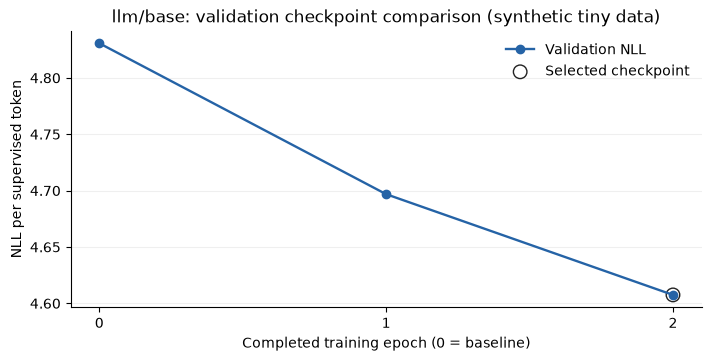

Validation supervised tokens: 18


In [5]:
import json
import matplotlib.pyplot as plt

baseline_validation = json.loads((RUN_DIR / "baseline_validation.json").read_text())
epochs = [0] + [r["epoch"] for r in report["training"]["history"]]
nll = [baseline_validation["metrics"]["nll"]] + [
    r["validation"]["metrics"]["nll"] for r in report["training"]["history"]]
selected_epoch = report["training"]["best_epoch"]
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.plot(epochs, nll, color="#2563a6", marker="o", linewidth=1.7, label="Validation NLL")
ax.scatter([selected_epoch], [nll[epochs.index(selected_epoch)]],
           s=95, facecolors="none", edgecolors="#222222", label="Selected checkpoint")
ax.set(title=f"{cfg.kind}: validation checkpoint comparison (synthetic tiny data)",
       xlabel="Completed training epoch (0 = baseline)", ylabel="NLL per supervised token")
ax.set_xticks(epochs)
ax.grid(axis="y", alpha=0.2)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False)
fig.savefig(RUN_DIR / "validation-nll.png", dpi=140)
plt.show()
print("Validation supervised tokens:", baseline_validation["supervised_tokens"])

## 检查

### 5. 重载导出权重并推理

Full 导出为原生 Transformers 模型；LoRA 固定基座 revision，tiny/本地基座随包保存。
可选 merged 导出重载副本，不修改活动 adapter 模型。

In [6]:
model = BaseModel.load(report["export"], device="cpu")
response = model.generate(["the sky is"], max_new_tokens=8)
print("Generated continuation/response:", response)
metadata = json.loads((Path(report["export"]) / "advai_metadata.json").read_text())
print("Export format:", metadata["format"])
if cfg.training.method == "lora":
    merged_path = model.save(RUN_DIR / "merged-export", merged=True)
    merged = BaseModel.load(merged_path)
    assert merged.generate(["the sky is"], max_new_tokens=8) == response
    print("Merged export preserves greedy output:", merged_path)

Generated continuation/response: ['is is is is is is is is']
Export format: full


### 6. 验证已完成实验的恢复

`latest` 通过 `latest.json` 指向完整 Trainer checkpoint，包含 optimizer、scheduler 和 RNG。
推理 export 不能恢复训练；配置、数据、包版本或源码变更应创建新实验。

In [7]:
recovered = run(cfg, resume=RUN_DIR / "latest")
assert recovered["training"] == report["training"]
assert recovered["finetuned_test"] == report["finetuned_test"]
print("Completed checkpoint recovery preserves the selected test report.")

Completed checkpoint recovery preserves the selected test report.


## 下一步

### 7. 预览 Hugging Face 推理包

默认执行离线 dry-run。模型卡使用英文；原始记录、optimizer/RNG、凭据和日志不上传。
只有显式设置 `UPLOAD_TO_HUB=True` 并使用有权限的仓库才会上传。默认运行不创建 Hub 模型仓库。

替换为按来源分组的领域数据，并评估目标任务。QLoRA、packing、多设备和偏好训练尚未实现。
详见 [指南](../../../docs/llm.zh-CN.md)。

In [8]:
from advai_notebooks.llm.base.publish import publish
from advai_notebooks.common.artifacts import write_json

UPLOAD_TO_HUB = False
REPO_ID = "widebluesky/wbs-llm-base-demo"
publication = publish(report["export"], REPO_ID, dry_run=not UPLOAD_TO_HUB, private=True)
write_json(RUN_DIR / "publication.json", publication)
print({key: publication[key] for key in ("status", "repo_id", "private")})
print("Inference package files:", len(publication["files"]))

{'status': 'dry_run', 'repo_id': 'widebluesky/wbs-llm-base-demo', 'private': True}
Inference package files: 8
